# AI infrastructure depreciation: accounting method, estimate revisions and investor interpretation

**Meta and Amazon · FY2021–2025 focus · HE3112 Financial Accounting for Economists**

**Research question:** How sensitive is reported profitability to the timing of infrastructure cost recognition, and what can investors infer from management's useful-life revisions?

This project has two parts:

1. **Method choice:** What would historical earnings look like if additions to Meta's server pool since 2021 had followed standard accelerated depreciation schedules? This is an explicitly conditional model, informed by reported server balances and actual annual financial results.
2. **Actual estimate revisions:** How much did Meta's and Amazon's disclosed useful-life changes affect earnings, and what happened to stock returns around the announcement bundles?

The assignment asks for an accounting choice, its financial effects and economic implications. Part A supplies the method experiment; Part B supplies actual company changes. Neither a simulated schedule nor a stock-price reaction proves management chose an incorrect useful life.

**Reading guide:** establish the accounting distinction and source data → assess server exposure → run the historical method experiment → examine actual revisions and earnings bridges → interpret market reactions → make a brokerage recommendation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from analysis_support import (OUTPUT, URLS, load_server_disclosures,
    no_change_counterfactual, depreciation_weights, expansion_model,
    load_prices, market_events, event_study)

ROOT = Path.cwd()
assert (ROOT / 'data/depreciation_analysis.xlsx').exists(), 'Run from the project directory.'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold', 'font.size':10, 'axes.grid':True,
                     'grid.alpha':.18, 'savefig.bbox':'tight'})
COLORS = {'Meta':'#2563a6', 'Amazon':'#d27816', 'Straight-line':'#64748b',
          'Sum-of-years-digits':'#8b5ca6', 'Double-declining':'#d45546'}
pd.set_option('display.float_format', lambda x:f'{x:,.3f}')
pd.set_option('display.max_colwidth', 100)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / (name+'.png'), dpi=180)
    plt.savefig(FIGURES / (name+'.svg'))
    plt.show()

numbers = pd.read_excel(ROOT/'data/depreciation_analysis.xlsx', sheet_name='numbers')
numbers = numbers.rename(columns={'implied_useful_life_yrs':'gross_ppe_to_depreciation_ratio_yrs'})
numbers = numbers.sort_values(['ticker','fiscal_year']).reset_index(drop=True)
numbers['company'] = numbers.ticker.map({'META':'Meta','AMZN':'Amazon'})
for field in ['revenue','operating_income','net_income','depreciation','capex','ppe_gross','ppe_net']:
    numbers[field+'_bn'] = numbers[field]/1e9  # preserve losses; never use abs()
numbers['op_margin_pct'] = 100*numbers.operating_income/numbers.revenue
numbers['ni_margin_pct'] = 100*numbers.net_income/numbers.revenue
assert not numbers.duplicated(['ticker','fiscal_year']).any()
assert (numbers.revenue>0).all()
assert np.allclose(numbers.ppe_gross-numbers.accumulated_depreciation,numbers.ppe_net)
assert numbers.query("ticker=='AMZN' and fiscal_year==2022").net_income.iloc[0] < 0

servers = load_server_disclosures(ROOT/'data/depreciation_analysis.xlsx')
servers.to_csv(OUTPUT/'server_disclosures.csv', index=False)
print('Loaded annual statements and independently extracted server-note data.')

Loaded annual statements and independently extracted server-note data.


## 1. Accounting: method, useful life and impairment answer different questions

Both companies report under **US GAAP**, and both disclose straight-line depreciation of equipment. IAS 16 provides a useful classroom comparison; it is not their governing reporting framework. Under US GAAP, useful-life revisions are changes in estimates applied prospectively. FASB's discussion of ASC 250 also explains that changing a depreciation method is a change in estimate effected by a change in accounting principle. Our historical experiment is an analyst's hypothetical, not the required accounting for adopting a new method today. [FASB discussion of ASC 250](https://storage.fasb.org/PCC%20SBAC-Topic%205-20240625.pdf)

| Decision | What changes? | What it does not establish |
|---|---|---|
| Method: straight-line vs accelerated | Allocation of depreciable cost across asset ages | The actual economic value of the asset |
| Useful life: e.g. six to five years | Remaining period over which book value is allocated | That management adopted a declining-balance method |
| Early retirement / impairment | Recognition of an earlier end to use or loss of recoverability | One common decline curve for the whole fleet |

Depreciation allocates historical cost; it does not mark equipment to resale prices. IAS 16 §§56, 60–62 discusses obsolescence, consumption patterns and possible methods. A new GPU generation can reduce older equipment's relative competitiveness without reducing its physical throughput. Old equipment may also find other workloads. These possibilities require evidence, not an assumed universal decay rate. [IAS 16](https://www.ifrs.org/content/dam/ifrs/publications/pdf-standards/english/2022/issued/part-a/ias-16-property-plant-and-equipment.pdf)

**Why retain straight-line?** Stable service capacity is one plausible explanation. Fleet heterogeneity and uncertain future workloads can also make a precise accelerated pattern hard to support. These are analytical explanations: the filings confirm the chosen method, but do not establish each of these as management's stated motive. High margins or the desire to protect earnings are not evidence of the correct consumption pattern.

**A revealing within-company comparison:** Amazon's 2025 10-K describes predominantly accelerated amortisation of original video content using expected viewing patterns, while equipment follows straight-line. This shows that Amazon does use uneven cost allocation where it estimates an appropriate consumption pattern. Content is a different asset class, so it does not prove the same method is appropriate for GPUs. [Amazon, Note 1, pp. 47–49](https://www.sec.gov/Archives/edgar/data/1018724/000101872426000004/amzn-20251231.htm)

## 2. What is observed, and where does it come from?

| Input | Origin | Use |
|---|---|---|
| Revenue, operating income, net income, total PP&E and equipment depreciation | `depreciation_analysis.xlsx`, `numbers`; existing SEC company-facts extraction | Reported historical financial base |
| Server gross cost and Meta server depreciation | `depreciation_analysis.xlsx`, `server_disclosures`; built by `depreciation_notes.py` from local 10-K HTML | Server exposure, Meta cohort proxy, baseline checks |
| Useful-life revision effects | Explicit management disclosures in 2024/2025 10-Ks | Mechanical no-change earnings bridges |
| Filing-passage locations | `depreciation_analysis.xlsx`, `notes`; local HTML filename and SEC link | Find and verify extracted passages in the original filing; no PDF page numbers are generated |
| Adjusted stock/benchmark closes | Yahoo Finance via yfinance; cached CSV | Descriptive event study |

The `*_sec_statements.xlsx` exports are supplementary statement files; this notebook does not use them as its numeric input. Keyword-extracted sentences in the original workbook help locate notes, but are not a complete structured extraction of their tables. The `server_disclosures` sheet is built upstream by `depreciation_notes.py`; the notebook only reads it. Generated tables use **USD billions**.

**Correction to earlier discussion:** Meta's server/network gross cost is **USD 98.040 billion**. The component rows sum to **USD 233.726 billion** of gross PP&E. After deducting **USD 57.326 billion** of accumulated depreciation, net PP&E is **USD 176.400 billion**. The heading “PP&E, net consists of” does not make each component a net value. Meta's 2025 server share is about **41.9% of gross PP&E**, not 55.6% of net PP&E. Amazon's comparable broad category share is about **32.3%**. Category boundaries still differ; neither category isolates AI GPUs. [Meta, Note 6, p. 107](https://www.sec.gov/Archives/edgar/data/1326801/000162828026003942/meta-20251231.htm) · [Amazon, Note 3, p. 54](https://www.sec.gov/Archives/edgar/data/1018724/000101872426000004/amzn-20251231.htm)

In the supplied filings, Amazon only separately presents server/network gross cost for **2024 and 2025** (both in the FY2025 filing). Earlier equipment totals mix servers with other equipment. Meta provides the longer series needed for Part A. Missing Amazon server depreciation remains missing; AWS depreciation is a segment total and cannot substitute for it.

In [2]:
display(servers[['ticker','fiscal_year','server_gross_bn','ppe_gross_bn','server_share_gross_pct',
                 'server_dep_bn','source_file','dep_source_file']])

,ticker,fiscal_year,server_gross_bn,ppe_gross_bn,server_share_gross_pct,server_dep_bn,source_file,dep_source_file
0,AMZN,2024,113.156,394.055,28.716,NaN,AMZN_10-K_FY2025.htm,NaN
1,AMZN,2025,172.492,534.098,32.296,NaN,AMZN_10-K_FY2025.htm,NaN
2,META,2020,20.544,61.051,33.651,4.380,META_10-K_FY2021.htm,META_10-K_FY2022.htm
3,META,2021,25.584,77.889,32.847,4.940,META_10-K_FY2022.htm,META_10-K_FY2023.htm
4,META,2022,34.330,104.493,32.854,5.290,META_10-K_FY2023.htm,META_10-K_FY2024.htm
5,META,2023,46.838,129.721,36.107,7.320,META_10-K_FY2024.htm,META_10-K_FY2025.htm
6,META,2024,68.397,164.663,41.538,11.340,META_10-K_FY2025.htm,META_10-K_FY2025.htm
7,META,2025,98.040,233.726,41.947,13.360,META_10-K_FY2025.htm,META_10-K_FY2025.htm


### Observed indicators: exposure and investment pressure

These figures answer different questions. Server share measures infrastructure exposure; depreciation/revenue measures the recognised expense burden; capex/depreciation compares current cash purchases with cost allocation from multiple historical cohorts. None estimates a server's lifespan.

Here `n.capex` is the SEC company-facts cash-flow amount for **purchases of PP&E**, before separately reported adjustments. It is not identical to each company's headline capex measure. For example, Amazon's FY2025 cash capex nets USD 3.499bn of PP&E sale proceeds/incentives from USD 131.819bn of purchases, giving USD 128.320bn. Meta's FY2025 headline capex includes USD 2.524bn of finance-lease principal in addition to USD 69.691bn of PP&E purchases, giving USD 72.215bn. So this chart specifically compares cash PP&E purchases with depreciation—not each company's headline capex with depreciation. The measure is consolidated, not server-specific, and its definition limits strict cross-company comparability. [Amazon FY2025 10-K](https://www.sec.gov/Archives/edgar/data/1018724/000101872426000004/amzn-20251231.htm) · [Meta FY2025 10-K](https://www.sec.gov/Archives/edgar/data/1326801/000162828026025534/meta-12312025x10kars.htm)

Amazon's depreciation field represents PP&E depreciation **and amortisation**, including finance-lease asset amortisation. Do not substitute its much broader cash-flow D&A figure.

The dotted line marks ChatGPT's public launch on 30 November 2022 as a **context marker, not a causal cutoff**. The Transformer architecture was published in 2017—before this chart's company-wide series starts—and GPT-3 was announced in 2020. AI research and infrastructure investment predate ChatGPT, while these annual figures also reflect other business and accounting changes. [Transformer paper](https://arxiv.org/abs/1706.03762) · [GPT-3 announcement](https://openai.com/index/language-models-are-few-shot-learners/) · [ChatGPT launch](https://openai.com/index/chatgpt/)

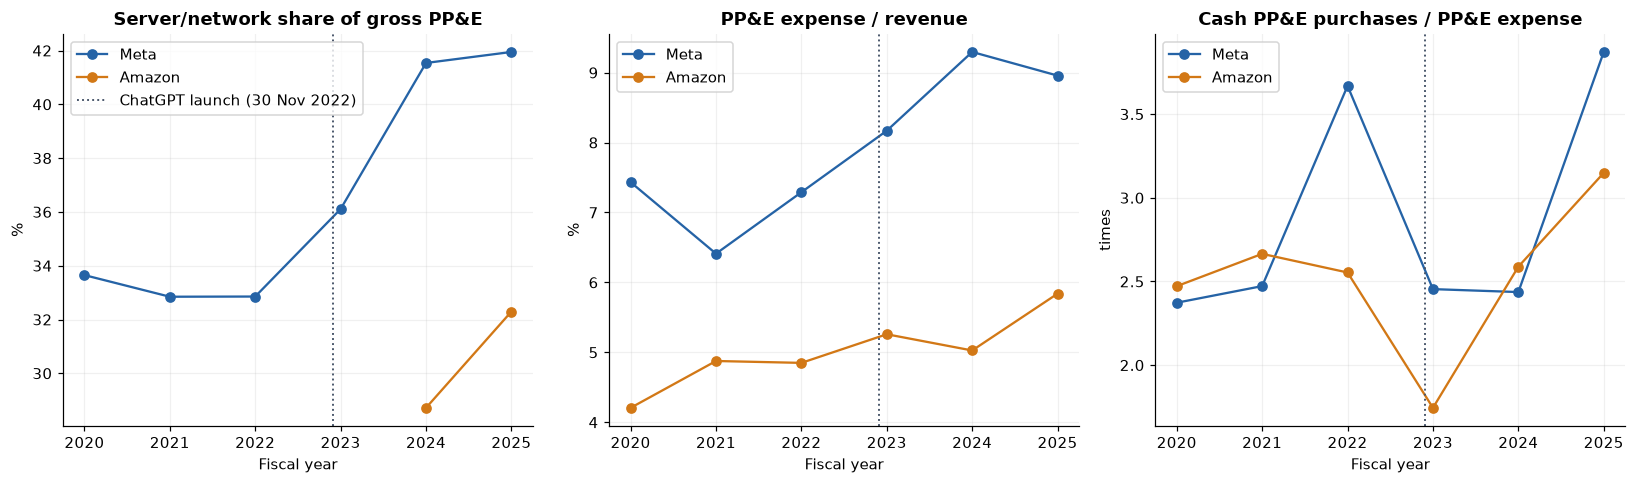

,company,capex_bn,depreciation_bn,purchases_to_dep,op_margin_pct,ni_margin_pct
8,Amazon,131.820,41.860,3.150,11.160,10.830
17,Meta,69.690,18.000,3.870,41.440,30.080


In [3]:
fig,axes = plt.subplots(1,3,figsize=(15,4.5))
chatgpt_launch_x = 2022 + 333/365  # 30 Nov 2022 on a calendar-year axis
for ticker, name in [('META','Meta'),('AMZN','Amazon')]:
    s=servers.query('ticker==@ticker').sort_values('fiscal_year')
    n=numbers.query('ticker==@ticker and fiscal_year>=2020')
    axes[0].plot(s.fiscal_year,s.server_share_gross_pct,'o-',color=COLORS[name],label=name)
    axes[1].plot(n.fiscal_year,100*n.depreciation/n.revenue,'o-',color=COLORS[name],label=name)
    axes[2].plot(n.fiscal_year,n.capex/n.depreciation,'o-',color=COLORS[name],label=name)
for ax,title,unit in zip(axes,['Server/network share of gross PP&E','PP&E expense / revenue','Cash PP&E purchases / PP&E expense'],['%','%','times']):
    ax.axvline(chatgpt_launch_x,color='#475569',linestyle=':',linewidth=1.25,
               label='ChatGPT launch (30 Nov 2022)' if ax is axes[0] else None)
    ax.set(title=title,ylabel=unit,xlabel='Fiscal year'); ax.legend()
    ax.set_xticks(range(2020,2026))
savefig('01_observed_exposure')

latest=numbers.query('fiscal_year==2025').copy()
latest['purchases_to_dep']=latest.capex/latest.depreciation
display(latest[['company','capex_bn','depreciation_bn','purchases_to_dep','op_margin_pct','ni_margin_pct']].round(2))

Amazon spends more dollars, but Meta's 2025 purchases/depreciation ratio is higher. That contradicts the initial hypothesis that Amazon necessarily has the larger ratio. Neither this ratio nor consolidated margins reveals a willingness to recognise depreciation. Retail and advertising also have different business economics, so cross-company margin levels cannot adjudicate the correct server life.

Net margin also reflects non-depreciation items: Meta disclosed a **USD 15.93 billion** tax charge in Q3 2025. We therefore prioritise operating-income and operating-margin effects when isolating depreciation, while showing net-income effects separately. [Meta FY2025, provision for income taxes](https://www.sec.gov/Archives/edgar/data/1326801/000162828026003942/meta-20251231.htm)

For Meta, the server-specific series provides a better denominator than total PP&E. Depreciation divided by average gross server cost is an **expense-intensity indicator**. Investment timing, fully depreciated assets, disposals and life revisions all affect it; its reciprocal is not a measured useful life.

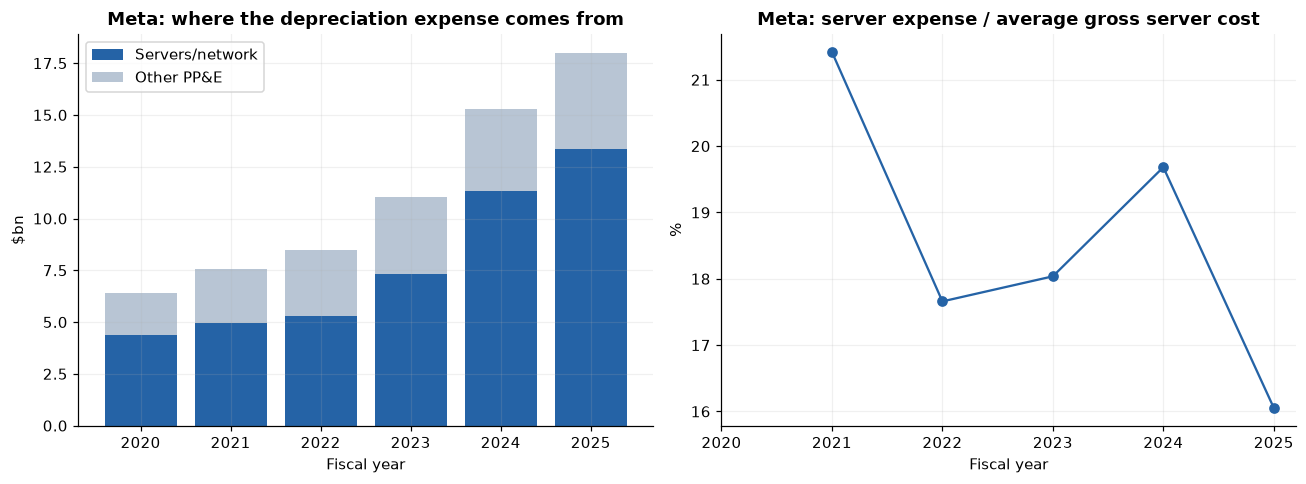

In 2025, servers/network account for **74.2%** of Meta's PP&E depreciation. This is a meaningful concentration measure even though the economic depreciation curve remains unknown.

In [4]:
meta=servers.query("ticker=='META'").sort_values('fiscal_year').copy()
meta['average_server_gross_bn']=(meta.server_gross_bn+meta.server_gross_bn.shift())/2
meta['server_expense_intensity_pct']=100*meta.server_dep_bn/meta.average_server_gross_bn
meta=meta.merge(numbers[['ticker','fiscal_year','depreciation_bn']],on=['ticker','fiscal_year'])
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].bar(meta.fiscal_year,meta.server_dep_bn,label='Servers/network',color=COLORS['Meta'])
axes[0].bar(meta.fiscal_year,meta.depreciation_bn-meta.server_dep_bn,bottom=meta.server_dep_bn,
            label='Other PP&E',color='#b8c5d4')
axes[0].set(title='Meta: where the depreciation expense comes from',ylabel='$bn',xlabel='Fiscal year'); axes[0].legend()
axes[1].plot(meta.fiscal_year,meta.server_expense_intensity_pct,'o-',color=COLORS['Meta'])
axes[1].set(title='Meta: server expense / average gross server cost',ylabel='%',xlabel='Fiscal year')
for ax in axes: ax.set_xticks(range(2020,2026))
savefig('02_meta_server_expense')
display(Markdown(f"In 2025, servers/network account for **{13.36/18*100:.1f}%** of Meta's PP&E depreciation. This is a meaningful concentration measure even though the economic depreciation curve remains unknown."))

## Part A — Historical method experiment, 2021–2025

### 3. What can be simulated credibly?

We can calculate the consequences of an assumed schedule. We cannot identify the unique economic depreciation curve from annual gross balances and expense totals. Gross server cost follows:

$$

G_t=G_{t-1}+A_t-R_t+X_t,

$$

where additions $A$, gross removals $R$, and reclassifications/other changes $X$ are not all separately disclosed. Multiple age distributions and retirement histories can produce the same reported totals. Meta's depreciation provides a useful check, but does not solve all those unknowns; Amazon has even fewer server-specific observations.

**Our tractable question:** What if estimated additions to Meta's server/network pool **since 2021** had used accelerated methods instead of a common straight-line benchmark? Existing pre-2021 assets retain their reported treatment. This partial-pool experiment makes the missing opening age distribution manageable and fits the assignment's allowance for a structured hypothetical based on real statements.

| Assumption | Main case | Sensitivity / limitation |
|---|---|---|
| Additions | Annual growth in gross server cost | Add removals equal to 5% or 10% of prior-year gross cost; ignore FX/reclassifications |
| Opening pool | Unchanged accounting treatment | Sensitivity removals assumed to be fully depreciated opening assets; cannot exceed opening gross stock |
| Life | Five years for all modelled additions | Six-year alternative; historical actual lives were not constant |
| Timing | Half-year convention | Approximation to equipment entering service through the year |
| Residual | Zero | Assumption, not a disclosed measured resale value |
| Alternative methods | Sum-of-years-digits; double-declining with switch to straight-line | Standard formulae; rates are not empirically fitted to GPU obsolescence |
| Revenue and other business activity | Each year's actual results | Accounting-only experiment; behavioural responses excluded |
| Tax effect on incremental expense | 21% illustrative | 15% and 25% sensitivity; actual tax-book differences are more complex |

The central additions proxy misses replacement investment when disposals occur. It is not reported server capex and is not guaranteed to be a lower bound when reclassifications occur.

In [5]:
START, END = 2021, 2025
central=expansion_model(servers,numbers,life=5,replacement=0.,tax=.21,start=START,end=END)
all_models=pd.concat([expansion_model(servers,numbers,life=L,replacement=r,tax=t,start=START,end=END)
    for L in [5,6] for r in [0.,.05,.10] for t in [.15,.21,.25]],ignore_index=True)
addition_check=central.query("method=='Straight-line'")[['fiscal_year','inferred_additions_bn',
    'model_sl_bn','reported_server_dep_bn','unmodelled_server_residual_bn']]
display(addition_check.round(3))
assert np.isclose(addition_check.inferred_additions_bn.sum(),98.040-20.544)
assert (addition_check.unmodelled_server_residual_bn>=0).all()

,fiscal_year,inferred_additions_bn,model_sl_bn,reported_server_dep_bn,unmodelled_server_residual_bn
0,2021,5.040,0.504,4.940,4.436
1,2022,8.746,1.883,5.290,3.407
2,2023,12.508,4.008,7.320,3.312
3,2024,21.559,7.415,11.340,3.925
4,2025,29.643,12.535,13.360,0.825


The residual column is observed server depreciation minus the modelled straight-line charge for post-2020 additions. A negative value would contradict interpreting that assumed cohort charge as a component of reported server depreciation. A nonnegative residual is only a feasibility check: it is **not proof** that the model reconstructs the actual fleet. We leave this residual unchanged in the method experiment.

### 4. Connect asset-age schedules to actual calendar years

For useful life $L$, straight-line weights are $1/L$, while sum-of-years-digits weights are $(L-a+1)/[L(L+1)/2]$ at age $a$; those full-year schedules are split across adjacent calendar years under the half-year convention. Double-declining is calculated directly over half-year/full-year/half-year periods: apply $2/L$ to remaining book value for the period, but switch to straight-line over remaining useful life when that charge is higher. For a five-year life this gives 20%, 32%, 19.2%, 11.52%, 11.52%, and 5.76%. All methods allocate exactly the same cost over a completed cohort's life.

Annual fleet expense is the sum across acquisition cohorts: $D_t^m=\sum_v A_v w^m_{t-v}$. A growing fleet can show rising annual depreciation even if each individual accelerated cohort has a declining charge. That distinction explains why an aggregate expense trend does not reveal the age-depreciation curve.

### Cohort-by-year attribution (central case)

Each cell below is the depreciation in that fiscal year attributable to additions from the column's acquisition year, in USD billions. Rows are depreciation years; columns are acquisition cohorts. The upper-right triangle is zero by construction: a future purchase cannot create earlier depreciation. These tables use the central assumptions (five-year life, zero assumed removals) and the notebook's half-year convention. Row totals reconcile to the annual modelled depreciation for each method.

In [6]:
cohort_years=np.arange(START,END+1)
cohort_additions=addition_check.inferred_additions_bn.to_numpy()
for method in ['Straight-line','Sum-of-years-digits','Double-declining']:
    weights=depreciation_weights(method,5)
    attribution=np.zeros((len(cohort_years),len(cohort_years)))
    for vintage_idx,amount in enumerate(cohort_additions):
        for year_idx in range(vintage_idx,len(cohort_years)):
            age_idx=year_idx-vintage_idx
            attribution[year_idx,vintage_idx]=amount*weights[age_idx]
    table=pd.DataFrame(attribution,
        index=[f'{year} depreciation' for year in cohort_years],
        columns=[f'{year} additions' for year in cohort_years])
    table['Total'] = table.sum(axis=1)
    table.loc['Total'] = table.sum(axis=0)
    expected=central.loc[central.method.eq(method)].sort_values('fiscal_year').cohort_dep_bn.to_numpy()
    assert np.allclose(table.loc[[f'{year} depreciation' for year in cohort_years],'Total'].to_numpy(),expected)
    assert np.allclose(np.triu(attribution,k=1),0)
    display(Markdown(f'**{method} — USD billions**'))
    display(table.round(3))

**Straight-line — USD billions**

,2021 additions,2022 additions,2023 additions,2024 additions,2025 additions,Total
2021 depreciation,0.504,0.000,0.000,0.000,0.000,0.504
2022 depreciation,1.008,0.875,0.000,0.000,0.000,1.883
2023 depreciation,1.008,1.749,1.251,0.000,0.000,4.008
2024 depreciation,1.008,1.749,2.502,2.156,0.000,7.415
2025 depreciation,1.008,1.749,2.502,4.312,2.964,12.535
Total,4.536,6.122,6.254,6.468,2.964,26.344


**Sum-of-years-digits — USD billions**

,2021 additions,2022 additions,2023 additions,2024 additions,2025 additions,Total
2021 depreciation,0.840,0.000,0.000,0.000,0.000,0.840
2022 depreciation,1.512,1.458,0.000,0.000,0.000,2.970
2023 depreciation,1.176,2.624,2.085,0.000,0.000,5.884
2024 depreciation,0.840,2.041,3.752,3.593,0.000,10.226
2025 depreciation,0.504,1.458,2.919,6.468,4.940,16.288
Total,4.872,7.580,8.756,10.061,4.940,36.209


**Double-declining — USD billions**

,2021 additions,2022 additions,2023 additions,2024 additions,2025 additions,Total
2021 depreciation,1.008,0.000,0.000,0.000,0.000,1.008
2022 depreciation,1.613,1.749,0.000,0.000,0.000,3.362
2023 depreciation,0.968,2.799,2.502,0.000,0.000,6.268
2024 depreciation,0.581,1.679,4.003,4.312,0.000,10.574
2025 depreciation,0.581,1.008,2.402,6.899,5.929,16.817
Total,4.750,7.235,8.906,11.211,5.929,38.029


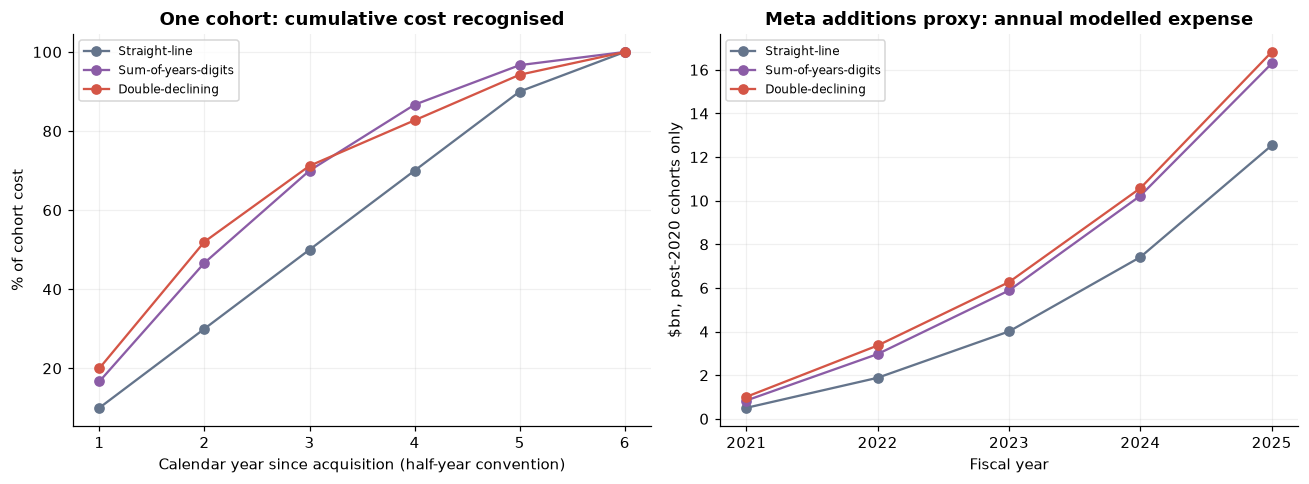

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for method in ['Straight-line','Sum-of-years-digits','Double-declining']:
    w=depreciation_weights(method,5)
    axes[0].plot(np.arange(1,len(w)+1),100*np.cumsum(w),'o-',label=method,color=COLORS[method])
    g=central[central.method.eq(method)]
    axes[1].plot(g.fiscal_year,g.cohort_dep_bn,'o-',label=method,color=COLORS[method])
axes[0].set(title='One cohort: cumulative cost recognised',xlabel='Calendar year since acquisition (half-year convention)',ylabel='% of cohort cost')
axes[1].set(title='Meta additions proxy: annual modelled expense',xlabel='Fiscal year',ylabel='$bn, post-2020 cohorts only')
axes[0].set_xticks(range(1,7)); axes[1].set_xticks(range(2021,2026))
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
savefig('03_method_and_cohorts')

### 5. What changes in historical profitability?

Let $\Delta D_t=D_t^{accelerated}-D_t^{model\ SL}$. We overlay **that difference** on actual results:

$$

OI_t^{scenario}=OI_t^{reported}-\Delta D_t,\qquad
NI_t^{scenario}=NI_t^{reported}-(1-\tau)\Delta D_t.

$$

Operating-margin effect is $-100\Delta D_t/Revenue_t$ percentage points. Net PP&E changes by $-\sum_{s\leq t}\Delta D_s$ for these retained cohorts. Revenue and cash purchases retain their observed year-by-year values; there is no constant-revenue forecast. Book depreciation alone does not change cash purchases or tax depreciation. The net-income tax calculation represents a simplified accounting tax effect, not a cash-tax forecast.

These are **incremental method scenarios against a modelled straight-line component**. The actual reported baseline includes historical estimate revisions and is not independently reproduced by our model. Consequently the scenario is not an audited restatement of the whole fleet.

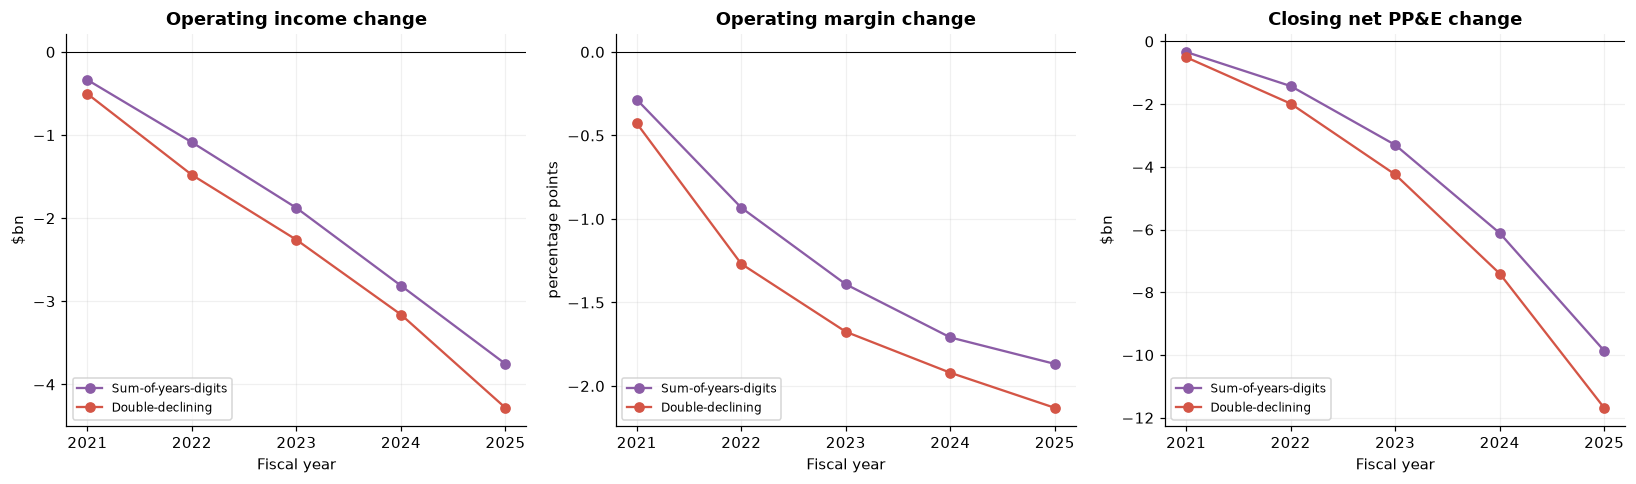

,fiscal_year,method,delta_dep_bn,adjusted_total_dep_bn,adjusted_op_bn,adjusted_ni_bn,op_margin_effect_pp,ni_margin_effect_pp,adjusted_ppe_net_bn
5,2021,Sum-of-years-digits,0.336,7.896,46.417,39.105,-0.285,-0.225,57.473
6,2022,Sum-of-years-digits,1.087,9.587,27.857,22.341,-0.932,-0.736,78.095
7,2023,Sum-of-years-digits,1.876,12.896,44.875,37.616,-1.391,-1.099,93.287
8,2024,Sum-of-years-digits,2.812,18.102,66.568,60.139,-1.709,-1.350,115.235
9,2025,Sum-of-years-digits,3.754,21.754,79.522,57.493,-1.868,-1.476,166.535
10,2021,Double-declining,0.504,8.064,46.249,38.972,-0.427,-0.338,57.305
11,2022,Double-declining,1.479,9.979,27.465,22.031,-1.269,-1.002,77.535
12,2023,Double-declining,2.260,13.280,44.491,37.313,-1.675,-1.323,92.344
13,2024,Double-declining,3.160,18.450,66.220,59.864,-1.921,-1.517,113.943
14,2025,Double-declining,4.282,22.282,78.994,57.075,-2.131,-1.683,164.715


**Size of the main-case effect:** in 2025, sum-of-years-digits reduces Meta's operating income by **USD 3.75bn** (1.87 margin points); double-declining reduces it by **USD 4.28bn** (2.13 points). These are **conditional model results**, not disclosed errors in Meta's accounts.

In [8]:
alternatives=central[central.method.ne('Straight-line')]
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
for method,g in alternatives.groupby('method',sort=False):
    for ax,column in zip(axes,['op_effect_bn','op_margin_effect_pp','cumulative_delta_bn']):
        y=-g[column] if column=='cumulative_delta_bn' else g[column]
        ax.plot(g.fiscal_year,y,'o-',color=COLORS[method],label=method)
for ax,title,unit in zip(axes,['Operating income change','Operating margin change','Closing net PP&E change'],['$bn','percentage points','$bn']):
    ax.axhline(0,color='black',lw=.7); ax.set(title=title,ylabel=unit,xlabel='Fiscal year'); ax.legend(fontsize=8)
    ax.set_xticks(range(2021,2026))
savefig('04_historical_method_effects')
display(alternatives[['fiscal_year','method','delta_dep_bn','adjusted_total_dep_bn','adjusted_op_bn',
                     'adjusted_ni_bn','op_margin_effect_pp','ni_margin_effect_pp','adjusted_ppe_net_bn']].round(3))
last=alternatives.query('fiscal_year==2025').set_index('method')
display(Markdown(f"**Size of the main-case effect:** in 2025, sum-of-years-digits reduces Meta's operating income by **USD {-last.loc['Sum-of-years-digits','op_effect_bn']:.2f}bn** ({-last.loc['Sum-of-years-digits','op_margin_effect_pp']:.2f} margin points); double-declining reduces it by **USD {-last.loc['Double-declining','op_effect_bn']:.2f}bn** ({-last.loc['Double-declining','op_margin_effect_pp']:.2f} points). These are **conditional model results**, not disclosed errors in Meta's accounts."))

### 6. How much depends on the assumptions?

The next figure changes useful life and the unobserved replacement rate, rather than presenting one guessed curve as the answer. Scenarios whose modelled straight-line component exceeds observed server depreciation in **any** year are marked infeasible as a component reconstruction and excluded from the summary range. Passing that check still leaves the model unverified. These ranges are scenario ranges, not statistical confidence intervals.

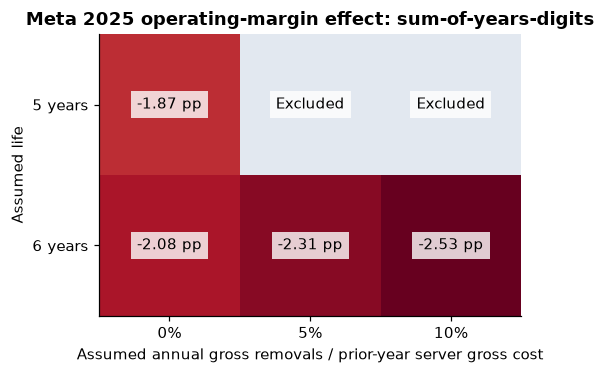

op_effect_bn        op_margin_effect_pp         \
                             min    max                 min    max   
method                                                               
Double-declining          -5.281 -4.282              -2.628 -2.131   
Sum-of-years-digits       -5.092 -3.754              -2.534 -1.868   

                    ni_effect_bn         
                             min    max  
method                                   
Double-declining          -4.489 -3.212  
Sum-of-years-digits       -4.328 -2.815

In [9]:
keys=['life','replacement','tax']
feasibility=all_models.groupby(keys).unmodelled_server_residual_bn.min().ge(-1e-9).rename('feasible').reset_index()
all_models=all_models.merge(feasibility,on=keys,validate='many_to_one')
heat=all_models.query("fiscal_year==2025 and method=='Sum-of-years-digits' and tax==0.21")
grid=heat.pivot(index='life',columns='replacement',values='op_margin_effect_pp')
valid=heat.pivot(index='life',columns='replacement',values='feasible')
fig,ax=plt.subplots(figsize=(7.5,3.5))
cmap=plt.get_cmap('RdBu').copy(); cmap.set_bad('#e2e8f0')
shown=grid.where(valid)
limit=np.nanmax(np.abs(shown.values))
im=ax.imshow(shown.values,cmap=cmap,vmin=-limit,vmax=limit)
ax.grid(False)
for i in range(len(grid)):
    for j in range(len(grid.columns)):
        text=f'{grid.iloc[i,j]:+.2f} pp' if valid.iloc[i,j] else 'Excluded'
        ax.text(j,i,text,ha='center',va='center',color='black',bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
ax.set(xticks=range(len(grid.columns)),xticklabels=[f'{x:.0%}' for x in grid.columns],
       yticks=range(len(grid)),yticklabels=[f'{x} years' for x in grid.index],
       xlabel='Assumed annual gross removals / prior-year server gross cost',ylabel='Assumed life',
       title='Meta 2025 operating-margin effect: sum-of-years-digits')
savefig('05_method_sensitivity')
valid_results=all_models.query("feasible and method!='Straight-line' and fiscal_year==2025")
display(valid_results.groupby('method')[['op_effect_bn','op_margin_effect_pp','ni_effect_bn']].agg(['min','max']).round(3))

**Interpretation.** Accelerated allocation shifts expense toward newer cohorts. With rapid investment growth, new cohorts can keep the annual earnings penalty large even after older cohorts reach their low-expense years. For a fixed cohort, the lifetime expense is unchanged; the future reversal is outside some of our five-year window. Reduced book profit alone does not mean a project's economic return or cash flow worsened.

This is a defensible hypothetical dimension of the project. It does not establish that straight-line is wrong. Public disclosures permit a sensitivity calculation, but leave acquisitions, disposals, age mix and workload economics underidentified. An attempt to estimate Amazon's server depreciation by multiplying total depreciation by server asset share would assume equal depreciation intensity across servers, buildings and other assets. We do not have evidence for that assumption.

## Part B — Actual changes, disclosed earnings effects and market reactions

### 7. The evidence is about revised expectations, not a proven nonlinear law

The timeline distinguishes an estimate's **effective date** from when investors learned of it. Life revisions can produce breaks in annual accounting charges and a piecewise-linear book-value path. They do not, by themselves, demonstrate a nonlinear economic consumption function.

Amazon's early-retirement decision provides stronger evidence of a specific disruption than a general benchmark improvement: its FY2024 report records approximately **USD 0.920 billion** of accelerated depreciation and related charges in Q4 2024. It separately forecast a **USD 0.6 billion** 2025 operating-income effect from continuing accelerated depreciation. The latter was a forecast, not an additional verified realised 2025 charge to add to the **USD 1.4 billion** estimate-change effect. [Amazon FY2024, Note 1, pp. 41–42](https://www.sec.gov/Archives/edgar/data/1018724/000101872425000004/amzn-20241231.htm)

External performance evidence supports the possibility of competitive pressure: MLPerf v4.1 reported improved best training times, while measuring complete hardware/software systems. Such benchmarks do not measure an existing server's dollar benefit consumption and cannot calibrate our depreciation weights. [MLCommons, November 2024](https://mlcommons.org/2024/11/new-mlperf-training-v4-1-benchmarks-highlight-industrys-focus-on-new-systems-and-generative-ai-applications/)

,date,company,event,interpretation
0,2024-01-01,Amazon,Effective: servers 5 → 6 years,FY2024 effect: expense −$3.2bn
1,2024-02-01,Amazon,Announcement: FY2023 earnings release,Server-life extension included in Q1 guidance
2,2024-12-31,Amazon,Q4 2024: early-retirement decisions,"Quarter marker, not precise decision date; $0.920bn charges"
3,2025-01-01,Meta,Effective: most server/network lives to 5.5 years,FY2025 effect: expense −$2.92bn
4,2025-01-01,Amazon,Effective: subset 6 → 5 years,FY2025 effect: expense +$1.4bn
5,2025-01-29,Meta,Announcement: FY2024 earnings release,Expected FY2025 expense reduction ≈$2.9bn
6,2025-02-06,Amazon,FY2024 results/call; 10-K follows Feb 7,Shortening/retirements discussed in this disclosure bundle


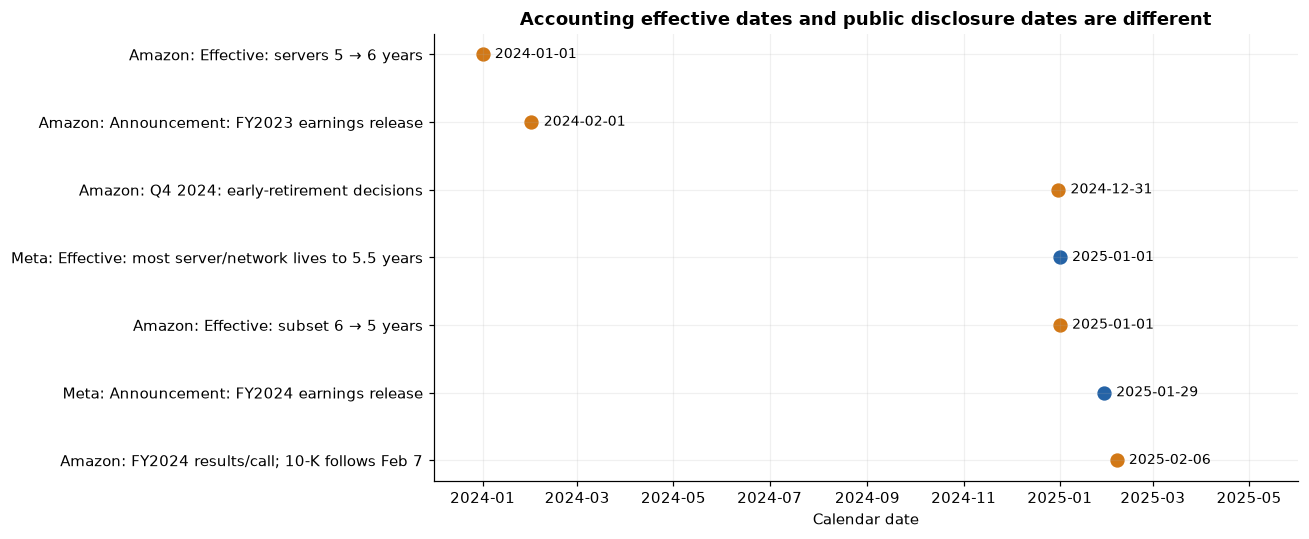

In [10]:
timeline=pd.DataFrame([
    ['2024-01-01','Amazon','Effective: servers 5 → 6 years','FY2024 effect: expense −$3.2bn'],
    ['2024-02-01','Amazon','Announcement: FY2023 earnings release','Server-life extension included in Q1 guidance'],
    ['2024-12-31','Amazon','Q4 2024: early-retirement decisions','Quarter marker, not precise decision date; $0.920bn charges'],
    ['2025-01-01','Meta','Effective: most server/network lives to 5.5 years','FY2025 effect: expense −$2.92bn'],
    ['2025-01-01','Amazon','Effective: subset 6 → 5 years','FY2025 effect: expense +$1.4bn'],
    ['2025-01-29','Meta','Announcement: FY2024 earnings release','Expected FY2025 expense reduction ≈$2.9bn'],
    ['2025-02-06','Amazon','FY2024 results/call; 10-K follows Feb 7','Shortening/retirements discussed in this disclosure bundle'],
],columns=['date','company','event','interpretation'])
display(timeline)
# Categorical event rows avoid overlapping labels for events one day apart.
fig,ax=plt.subplots(figsize=(12,5))
dates=pd.to_datetime(timeline.date)
for i,r in timeline.iterrows():
    ax.scatter(dates.iloc[i],i,color=COLORS[r.company],s=70)
    ax.annotate(r.date,(dates.iloc[i],i),xytext=(8,0),textcoords='offset points',va='center',fontsize=9)
ax.set_yticks(range(len(timeline)),timeline.company+': '+timeline.event)
ax.invert_yaxis(); ax.set_xlim(pd.Timestamp('2023-12-01'),pd.Timestamp('2025-06-01'))
ax.set_title('Accounting effective dates and public disclosure dates are different')
ax.set_xlabel('Calendar date')
savefig('06_evidence_timeline')

### 8. A transparent earnings bridge — not independent validation

Management's disclosed effect is an **input**. Reversing it does not independently verify it. For signed expense effect $\delta D$ and signed net-income effect $\delta NI$:

$$

D^{no\ change}=D^{reported}-\delta D,\quad
OI^{no\ change}=OI^{reported}+\delta D,\quad
NI^{no\ change}=NI^{reported}-\delta NI.

$$

The operating-income bridge assumes the disclosed PP&E expense effect is recognised in operating expenses, consistent with the policies disclosed. We use the companies' stated after-tax net-income effects rather than a guessed tax rate here.

All amounts below are in USD billions. Meta 2025: \(18.00 + 2.92 = 20.92\) depreciation; \(83.276 - 2.92 = 80.356\) operating income; \(60.458 - 2.59 = 57.868\) net income. Amazon 2025: \(41.86 - 1.40 = 40.46\) depreciation expense; \(79.975 + 1.40 = 81.375\) operating income; \(77.670 + 1.00 = 78.670\) net income.

Amazon's FY2024 filing **does disclose** the realised 5→6-year effect: depreciation expense decreased by **USD 3.2 billion**, and net income increased by **USD 2.5 billion**. The earlier notebook omitted it. The **USD 0.7 billion** forecast for shortening applied to the existing 2024 year-end pool; the realised **USD 1.4 billion** 2025 amount also covers acquisitions in 2025, so these are not directly comparable forecast/actual measurements. [Amazon FY2024](https://www.sec.gov/Archives/edgar/data/1018724/000101872425000004/amzn-20241231.htm) · [Amazon FY2025](https://www.sec.gov/Archives/edgar/data/1018724/000101872426000004/amzn-20251231.htm)

Each reversal removes the selected revision only. In particular, the 2024 Amazon bridge retains the separately reported early-retirement charges. Do not add these single-year effects across years to construct a cumulative no-change asset balance: ongoing effects of earlier revisions are not fully disclosed.

,company,fiscal_year,change,scope,dep_effect_bn,ni_effect_bn,depreciation_bn,dep_no_change_bn,operating_income_bn,op_no_change_bn,net_income_bn,ni_no_change_bn,op_margin_effect_pp,ni_effect_pct_reported
0,Amazon,2024,Servers: 5 → 6 years,2023 year-end assets + 2024 acquisitions,-3.200,2.500,32.067,35.267,68.593,65.393,59.248,56.748,0.502,4.220
1,Meta,2025,Most servers/network: extended to 5.5 years,Assets in service at 2024 year-end,-2.920,2.590,18.000,20.920,83.276,80.356,60.458,57.868,1.453,4.284
2,Amazon,2025,Subset servers/network: 6 → 5 years,2024 year-end assets + 2025 acquisitions,1.400,-1.000,41.860,40.460,79.975,81.375,77.670,78.670,-0.195,-1.287


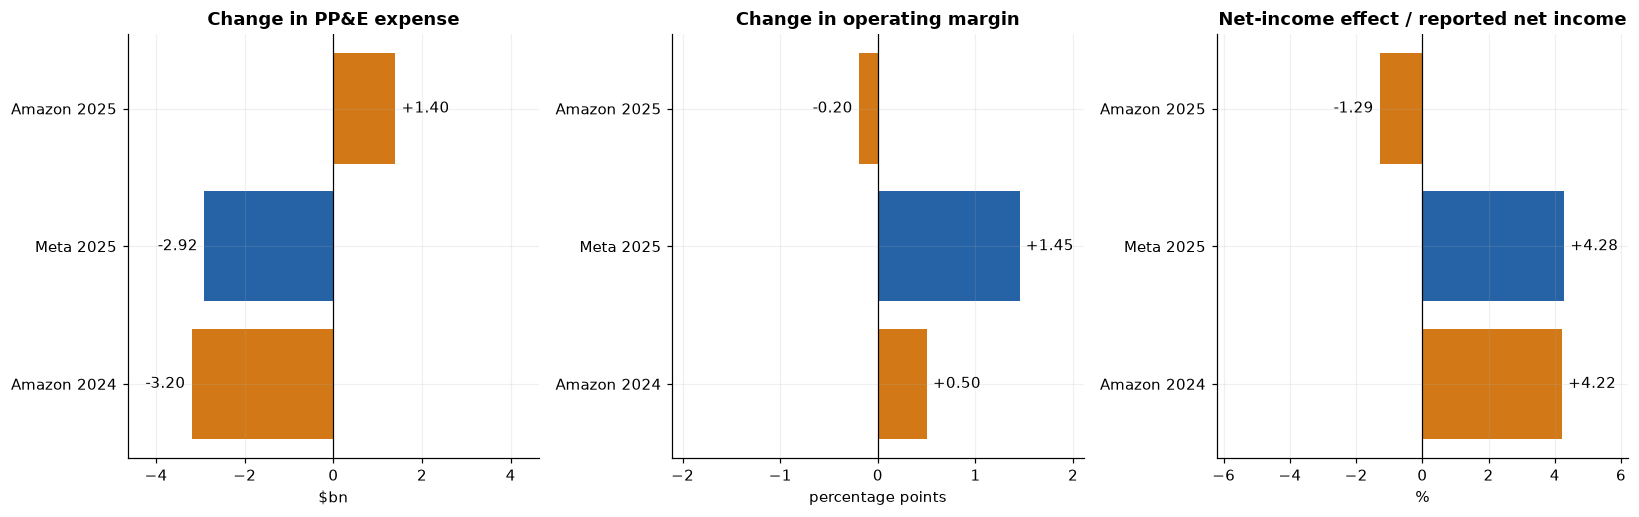

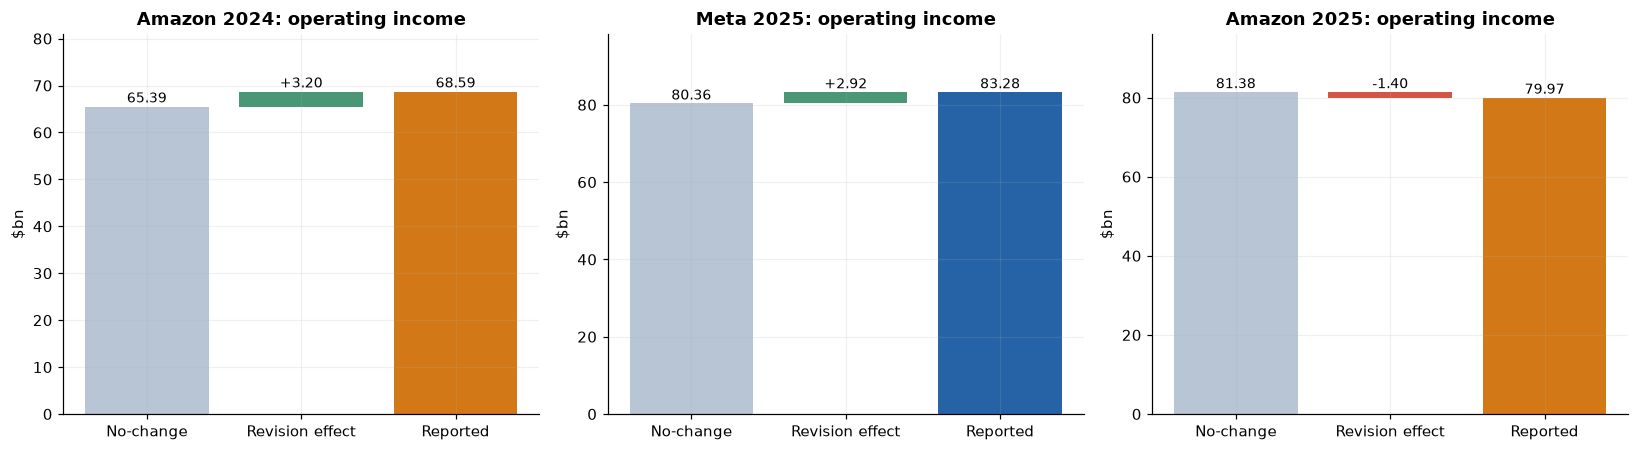

In [11]:
cf=no_change_counterfactual(numbers)
display(cf[['company','fiscal_year','change','scope','dep_effect_bn','ni_effect_bn',
    'depreciation_bn','dep_no_change_bn','operating_income_bn','op_no_change_bn',
    'net_income_bn','ni_no_change_bn','op_margin_effect_pp','ni_effect_pct_reported']].round(3))

fig,axes=plt.subplots(1,3,figsize=(15,4.8))
labels=cf.company+' '+cf.fiscal_year.astype(str)
for ax,col,title,unit in zip(axes,['dep_effect_bn','op_margin_effect_pp','ni_effect_pct_reported'],
        ['Change in PP&E expense','Change in operating margin','Net-income effect / reported net income'],
        ['$bn','percentage points','%']):
    bars=ax.barh(labels,cf[col],color=[COLORS[x] for x in cf.company])
    ax.bar_label(bars,labels=[f'{v:+.2f}' for v in cf[col]],padding=4)
    ax.axvline(0,color='black',lw=.8); ax.set(title=title,xlabel=unit)
    limit=max(abs(cf[col]))*1.45; ax.set_xlim(-limit,limit)
savefig('07_disclosed_materiality')

fig,axes=plt.subplots(1,3,figsize=(15,4.2))
for ax,r in zip(axes,cf.itertuples()):
    values=[r.op_no_change_bn,-r.dep_effect_bn,r.operating_income_bn]
    bottoms=[0,r.op_no_change_bn if values[1]>=0 else r.operating_income_bn,0]
    heights=[values[0],abs(values[1]),values[2]]
    ax.bar(['No-change','Revision effect','Reported'],heights,bottom=bottoms,
           color=['#b8c5d4','#499775' if values[1]>0 else '#d45546',COLORS[r.company]])
    for x,v,h,b in zip(range(3),values,heights,bottoms):
        ax.text(x,b+h+1,f'{v:+.2f}' if x==1 else f'{v:.2f}',ha='center',fontsize=9)
    ax.set(title=f'{r.company} {r.fiscal_year}: operating income',ylabel='$bn',ylim=(0,max(values[0],values[2])*1.18))
savefig('08_operating_income_bridges')

**What the bridges establish.** Estimate revisions explain an identifiable portion of reported earnings, but do not establish intent, fraud or the economically correct life. Meta's server expense still rose despite the extension: investment growth can outweigh an expense-reducing estimate change. Amazon's lower consolidated margin does not justify delaying expense. Its 2024 extension and 2025 shortening also affect differently defined pools.

“Same AI revolution, different lives” is a useful opening question, but not evidence that the firms should choose identical lives. Workload mix, maintenance, utilisation and retirement plans can differ. Our strongest claim concerns sensitivity and disclosure, rather than asserting that one firm is wrong.

### 9. Market reactions: what moved around the announcements?

The previous 2026 filing-date study was a poor test of the original revisions: the changes were already disclosed in 2024/2025. We instead use the first full trading sessions after the relevant earnings announcements, with Amazon's 2025 window also covering its next-day 10-K. Meta's January 29, 2025 release explicitly announced the 5.5-year extension and expected savings of **USD 2.9 billion**. [Meta release, p. 2](https://investor.atmeta.com/files/doc_financials/2024/q4/Meta-12-31-2024-Exhibit-99-1-FINAL.pdf)

For Amazon, the February 1, 2024 release includes the server-life extension in guidance. The February 6, 2025 release/call and February 7 filing form the shortening disclosure bundle; the release itself does not contain the full estimate-change note. [Amazon 2024 release](https://ir.aboutamazon.com/news-release/news-release-details/2024/Amazon-com-Announces-Fourth-Quarter-Results/default.aspx) · [Amazon 2025 release](https://s2.q4cdn.com/299287126/files/doc_financials/2024/q4/AMZN-Q4-2024-Earnings-Release.pdf)

Method: adjusted daily close-to-close simple returns; SPY benchmark; OLS market model estimated over trading days **−250 to −31** (220 observations); event window **−10 to +10**. Abnormal return is actual return minus the estimated $\alpha+\beta R_{market}$. We also report the simple market-adjusted result as a sensitivity. CAR is the sum of abnormal returns, not a compounded portfolio return. The plot is rebased to zero at day −1, and offsets count trading sessions.

These are earnings-announcement bundles: sales, margins, forecasts and AI spending news arrive together. Three observations cannot identify the depreciation-specific causal price effect. A positive CAR after an extension is not evidence investors were fooled; a negative CAR after shortening is not evidence they dislike accurate accounting.

,label,ticker,announcement,day0,source,context
0,Amazon: extension,AMZN,2024-02-01,2024-02-02,https://ir.aboutamazon.com/news-release/news-release-details/2024/Amazon-com-Announces-Fourth-Qu...,"Q4 results, AWS growth, Q1 earnings guidance"
1,Meta: extension,META,2025-01-29,2025-01-30,https://investor.atmeta.com/files/doc_financials/2024/q4/Meta-12-31-2024-Exhibit-99-1-FINAL.pdf,"Q4 results, 2025 expense/capex guidance"
2,Amazon: shortening,AMZN,2025-02-06,2025-02-07,https://s2.q4cdn.com/299287126/files/doc_financials/2024/q4/AMZN-Q4-2024-Earnings-Release.pdf,"Q4 results/call and next-day 10-K; Q1 guidance, AI spending"


,event,day0,window,observations,market_model_car_pct,market_adjusted_car_pct,beta,estimation_observations
0,Amazon: extension,2024-02-02,"[-1,+1]",3,6.487,7.625,1.474,220
1,Amazon: extension,2024-02-02,"[0,+1]",2,5.851,6.305,1.474,220
2,Amazon: extension,2024-02-02,"[0,+5]",6,5.466,7.003,1.474,220
3,Meta: extension,2025-01-30,"[-1,+1]",3,2.673,2.635,1.587,220
4,Meta: extension,2025-01-30,"[0,+1]",2,1.715,1.866,1.587,220
5,Meta: extension,2025-01-30,"[0,+5]",6,3.499,4.389,1.587,220
6,Amazon: shortening,2025-02-07,"[-1,+1]",3,-1.384,-1.297,1.512,220
7,Amazon: shortening,2025-02-07,"[0,+1]",2,-1.974,-2.076,1.512,220
8,Amazon: shortening,2025-02-07,"[0,+5]",6,-5.144,-4.793,1.512,220


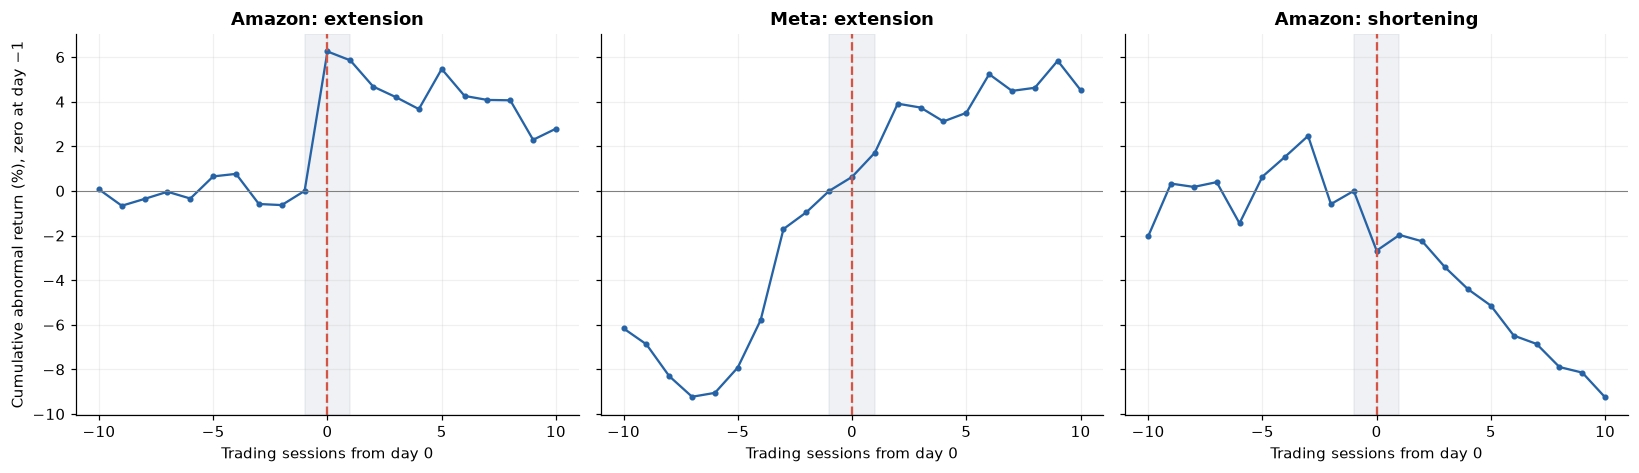

**What these data show:** the three-session market-model CAR is +6.49% for Amazon's extension bundle, +2.67% for Meta's extension bundle, and -1.38% for Amazon's shortening bundle. This sign pattern is compatible with many earnings/guidance explanations; it **does not isolate depreciation news**. Compare the alternate windows and benchmark method in the table before describing the direction or magnitude.

In [12]:
display(market_events())
prices=load_prices()
event_windows,event_results=event_study(prices)
display(event_results.round(3))
fig,axes=plt.subplots(1,3,figsize=(15,4.4),sharey=True)
for ax,(label,g) in zip(axes,event_windows.groupby('label',sort=False)):
    ax.plot(g.event_day,100*g.car,'o-',ms=3,color='#2563a6')
    ax.axvline(0,color='#d45546',ls='--'); ax.axhline(0,color='grey',lw=.7)
    ax.axvspan(-1,1,color='#94a3b8',alpha=.15)
    ax.set(title=label,xlabel='Trading sessions from day 0',xticks=[-10,-5,0,5,10])
axes[0].set_ylabel('Cumulative abnormal return (%), zero at day −1')
savefig('09_announcement_returns')
short_window=event_results.query("window=='[-1,+1]'").set_index('event')
display(Markdown(f"**What these data show:** the three-session market-model CAR is {short_window.loc['Amazon: extension','market_model_car_pct']:+.2f}% for Amazon's extension bundle, {short_window.loc['Meta: extension','market_model_car_pct']:+.2f}% for Meta's extension bundle, and {short_window.loc['Amazon: shortening','market_model_car_pct']:+.2f}% for Amazon's shortening bundle. This sign pattern is compatible with many earnings/guidance explanations; it **does not isolate depreciation news**. Compare the alternate windows and benchmark method in the table before describing the direction or magnitude."))

## 10. Brokerage interpretation and final judgement

The decision-useful finding is that infrastructure accounting changes **when** cost appears in earnings. A profitable business can look stronger after a life extension without receiving additional cash. Conversely, shortening a life can reduce earnings while conveying economically useful information about expected obsolescence.

| Finding | Investor implication | Boundary of the evidence |
|---|---|---|
| Accelerated methods change the timing of expense in the historical scenario | Compare operating margins with an assumption range, especially during rapid investment growth | Modelled additions and consumption patterns remain uncertain |
| Disclosed revisions materially alter current earnings | Reconcile reported earnings with the disclosed no-change bridge | This uses management's effect; it does not independently validate the estimate |
| Gross server exposure is observable for both firms, with unequal historical coverage | Request asset-class disclosures before normalising peers | Gross cost includes fully depreciated assets and does not identify AI GPUs |
| Amazon reports an actual early-retirement episode | Obsolescence risk can arrive in discrete episodes | A revision or charge does not identify a nonlinear fleet-wide curve |
| Stock prices move around announcement bundles | Consider cash-flow expectations, growth and risk alongside accounting news | Depreciation's separate price impact is not identified |

**Recommendation:** retain reported earnings as the starting point, show the disclosed revision bridge, and discuss the historical method scenario as a range conditional on assumptions. Monitor cash investment and asset utilisation alongside margins. Request annual server additions, removals, accumulated depreciation, fully depreciated assets still in use, and age/generation mix. Do not infer an economically correct server life from total gross PP&E/depreciation, or apply a five-year life to land, buildings and construction in progress.

**Answer to “why not nonlinear?”** Uneven economic obsolescence is plausible and specific retirement episodes are observable. Whether accelerated allocation better represents expected benefit consumption remains unproven for these server pools. The public evidence supports scrutiny of methods and useful-life estimates; it does not establish deliberate earnings manipulation. Amazon's content policy demonstrates the relevance of estimating the consumption pattern for each asset type.

For the four-page report, prioritise: (1) question/accounting distinction and asset exposure; (2) the Meta historical scenario and assumption sensitivity; (3) actual revisions and materiality; (4) market evidence, limitations and recommendation. Use the generated figures selectively—one chart per argument. A 10-slide presentation can follow the same order, reserving one slide for assumptions and one for the final recommendation.

Suggested AI-use statement: “We used ChatGPT/Codex to develop the analysis structure, locate disclosures, draft Python calculations and improve charts. We checked the source tables and assumptions, corrected extraction and interpretation errors, and take responsibility for the conclusions.” Adapt this to the group's actual verification work.

## 11. Reproducibility and audit trail

`ai_server_depreciation.ipynb` contains the narrative and chart code; `analysis_support.py` contains the analysis calculations, and `depreciation_notes.py` builds the source workbook from local HTML filings and SEC company facts. The input workbook is preserved. Results are exported to `data/final_analysis/analysis_tables.xlsx`, with CSVs and PNG/SVG figures alongside it. Prices are cached with download provenance; subsequent runs use that cache. Page references in the discussion use the filing's printed page labels; the HTML keyword-extraction sheet does not generate PDF page numbers.

The checks below test cost conservation, the counterfactual signs, the gross-to-net reconciliation and event-window counts. They validate calculation consistency, not the economic truth of assumed lives or management's estimated effects.

In [13]:
# Checks whose failure would change interpretation, rather than just presentation.
for method in ['Straight-line','Sum-of-years-digits','Double-declining']:
    for life in [5,6]:
        assert np.isclose(depreciation_weights(method,life).sum(),1)
        # Completed cohorts recognise the same cost regardless of timing.
        additions=addition_check.inferred_additions_bn.values
        assert np.isclose(np.convolve(additions,depreciation_weights(method,life)).sum(),additions.sum())
assert np.allclose(depreciation_weights('Double-declining',5),[.20,.32,.192,.1152,.1152,.0576])
assert np.isclose(servers.query("ticker=='META' and fiscal_year==2025").server_gross_bn.iloc[0],98.040)
assert np.isclose(cf.query("ticker=='META'").op_no_change_bn.iloc[0],80.356)
assert np.isclose(cf.query("ticker=='AMZN' and fiscal_year==2025").op_no_change_bn.iloc[0],81.375)
assert event_results.query("window=='[-1,+1]'").observations.eq(3).all()
assert event_results.estimation_observations.eq(220).all()

tables={'annual_financials':numbers,'server_disclosures':servers,
        'method_central':central,'method_sensitivity':all_models,'addition_checks':addition_check,
        'disclosed_bridges':cf,'timeline':timeline,'event_definitions':market_events(),
        'event_results':event_results,'event_windows':event_windows}
with pd.ExcelWriter(OUTPUT/'analysis_tables.xlsx',engine='openpyxl') as writer:
    for sheet,frame in tables.items():
        frame.to_excel(writer,sheet_name=sheet,index=False)
        frame.to_csv(OUTPUT/(sheet+'.csv'),index=False)
        ws=writer.sheets[sheet]
        ws.freeze_panes='C2'; ws.auto_filter.ref=ws.dimensions
        for column in ws.columns:
            ws.column_dimensions[column[0].column_letter].width=min(52,max(14,len(str(column[0].value))+2))
print('All accounting/model checks passed. Exported',len(tables),'tables and 9 figures (PNG + SVG).')

All accounting/model checks passed. Exported 10 tables and 9 figures (PNG + SVG).
